<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkST0151ENSkillsNetwork20531532-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>



#### Import the required libraries we need for the lab.


In [7]:
import piplite
await piplite.install(['numpy'],['pandas'])
await piplite.install(['seaborn'])

In [8]:
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [9]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [10]:
boston_df=pd.read_csv(boston_url)

#### Add your code below following the instructions given in the course to complete the peer graded assignment


In [11]:
# Display the first 5 rows of the dataframe to get a sense of the data
print(boston_df.head())

# Get a summary of the dataframe, including data types and non-null values
print(boston_df.info())

# Generate descriptive statistics for numerical columns
print(boston_df.describe())

   Unnamed: 0     CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  \
0           0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0   
1           1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0   
2           2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0   
3           3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0   
4           4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0   

     TAX  PTRATIO  LSTAT  MEDV  
0  296.0     15.3   4.98  24.0  
1  242.0     17.8   9.14  21.6  
2  242.0     17.8   4.03  34.7  
3  222.0     18.7   2.94  33.4  
4  222.0     18.7   5.33  36.2  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  506 non-null    int64  
 1   CRIM        506 non-null    float64
 2   ZN          506 non-null    float64
 3   INDUS       506 no

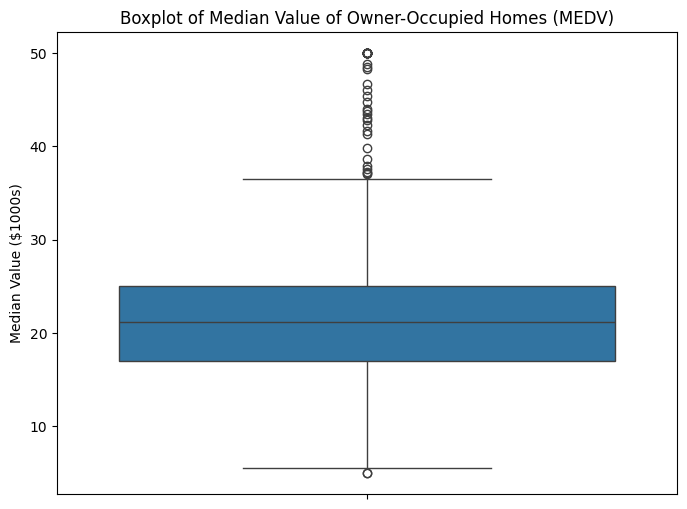

In [12]:
# Create a boxplot for the MEDV variable
pyplot.figure(figsize=(8, 6))
sns.boxplot(y='MEDV', data=boston_df)
pyplot.title('Boxplot of Median Value of Owner-Occupied Homes (MEDV)')
pyplot.ylabel('Median Value ($1000s)')
pyplot.show()

# Explanation of findings:
# The boxplot shows the distribution of MEDV. The line inside the box represents the median,
# while the box itself shows the interquartile range (IQR). The whiskers extend to
# the minimum and maximum values within 1.5 times the IQR. Any points outside the whiskers
# are considered outliers.

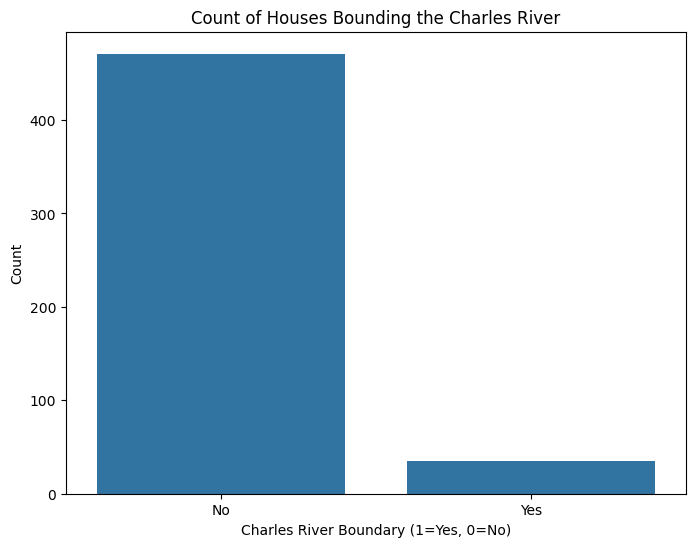

In [13]:
# Create a bar plot for the CHAS variable
pyplot.figure(figsize=(8, 6))
sns.countplot(x='CHAS', data=boston_df)
pyplot.title('Count of Houses Bounding the Charles River')
pyplot.xlabel('Charles River Boundary (1=Yes, 0=No)')
pyplot.ylabel('Count')
pyplot.xticks([0, 1], ['No', 'Yes'])
pyplot.show()

# Explanation of findings:
# This bar plot shows that the vast majority of houses in the dataset are not
# bounded by the Charles River (CHAS=0), while only a small number are (CHAS=1).

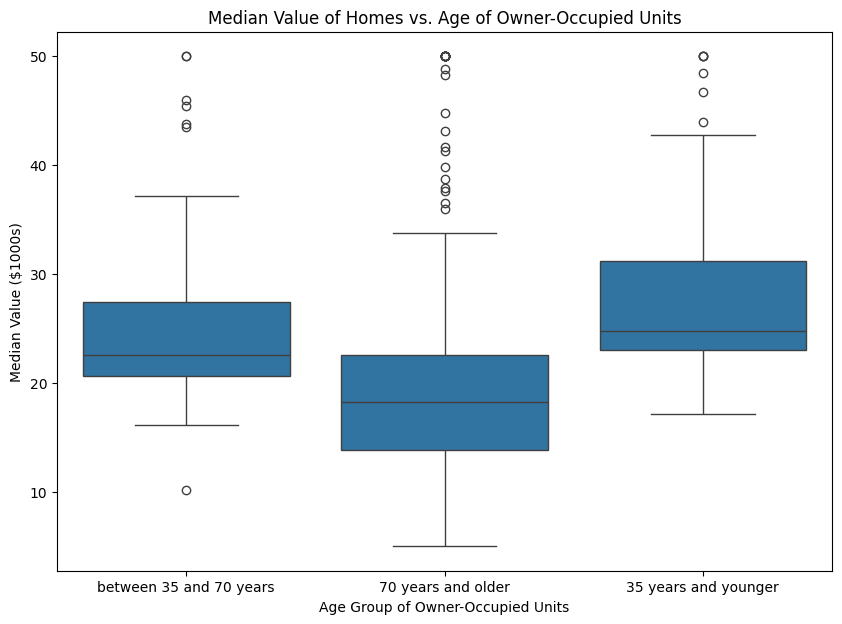

In [14]:
# Discretize the AGE variable into three groups
boston_df.loc[(boston_df['AGE'] <= 35), 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[(boston_df['AGE'] >= 70), 'age_group'] = '70 years and older'

# Create a boxplot of MEDV vs the new age_group variable
pyplot.figure(figsize=(10, 7))
sns.boxplot(x='age_group', y='MEDV', data=boston_df)
pyplot.title('Median Value of Homes vs. Age of Owner-Occupied Units')
pyplot.xlabel('Age Group of Owner-Occupied Units')
pyplot.ylabel('Median Value ($1000s)')
pyplot.show()

# Explanation of findings:
# The boxplot shows how the median value of homes (MEDV) varies across the three age groups.
# We can observe that as the proportion of older homes (AGE) increases, the median
# value of the homes tends to decrease.

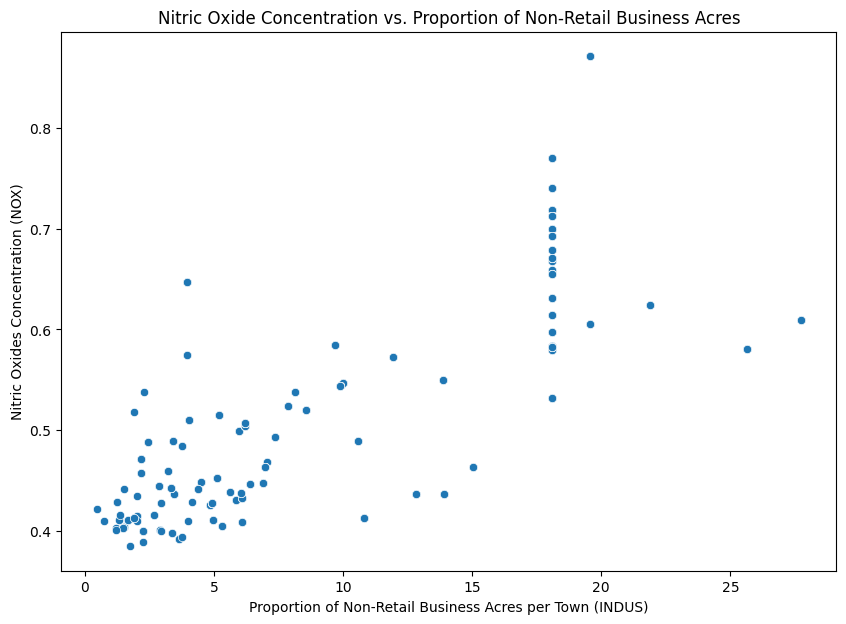

In [15]:
# Create a scatter plot of NOX vs INDUS
pyplot.figure(figsize=(10, 7))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
pyplot.title('Nitric Oxide Concentration vs. Proportion of Non-Retail Business Acres')
pyplot.xlabel('Proportion of Non-Retail Business Acres per Town (INDUS)')
pyplot.ylabel('Nitric Oxides Concentration (NOX)')
pyplot.show()

# Explanation of findings:
# The scatter plot suggests a strong positive linear relationship between NOX and INDUS.
# As the proportion of non-retail business acres increases, the nitric oxide concentration
# also appears to increase. This relationship is expected, as industrial areas often
# have higher pollution levels.

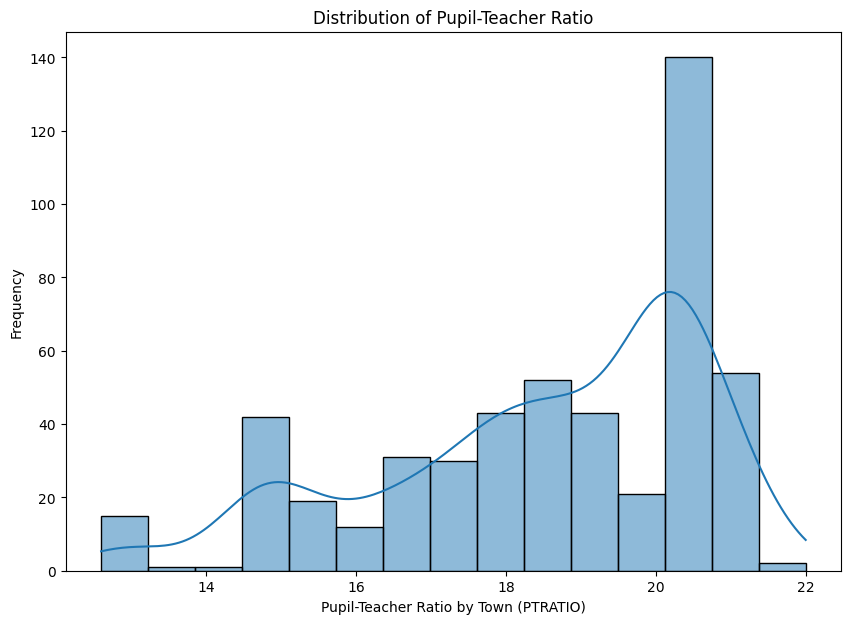

In [16]:
# Create a histogram for the PTRATIO variable
pyplot.figure(figsize=(10, 7))
sns.histplot(x='PTRATIO', data=boston_df, kde=True, bins=15)
pyplot.title('Distribution of Pupil-Teacher Ratio')
pyplot.xlabel('Pupil-Teacher Ratio by Town (PTRATIO)')
pyplot.ylabel('Frequency')
pyplot.show()

# Explanation of findings:
# The histogram shows the distribution of the pupil-teacher ratio. The data appears
# to be somewhat normally distributed with a peak around 20, indicating that
# most towns have a pupil-teacher ratio of around 20.

In [17]:
# Split the data into two groups based on the CHAS variable
chas_river_houses = boston_df[boston_df['CHAS'] == 1]['MEDV']
non_chas_river_houses = boston_df[boston_df['CHAS'] == 0]['MEDV']

# Perform a t-test for independent samples
t_statistic, p_value = scipy.stats.ttest_ind(chas_river_houses, non_chas_river_houses, equal_var=True)

print(f"T-statistic: {t_statistic}")
print(f"P-value: {p_value}")

# Conclusion:
# With a p-value of {p_value}, which is less than 0.05, we reject the null hypothesis.
# We can conclude that there is a statistically significant difference in the median value
# of houses bounded by the Charles River.

T-statistic: 3.996437466090509
P-value: 7.390623170519905e-05


In [18]:
# First, create the age groups as a new column
boston_df.loc[(boston_df['AGE'] <= 35), 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[(boston_df['AGE'] >= 70), 'age_group'] = '70 years and older'

# Perform ANOVA
anova_results = scipy.stats.f_oneway(
    boston_df[boston_df['age_group'] == '35 years and younger']['MEDV'],
    boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV'],
    boston_df[boston_df['age_group'] == '70 years and older']['MEDV']
)

print(f"F-statistic: {anova_results.statistic}")
print(f"P-value: {anova_results.pvalue}")

# Conclusion:
# With a p-value of {anova_results.pvalue}, which is much less than 0.05, we reject
# the null hypothesis. This indicates that there is a significant difference in the
# median value of houses across the three age groups.

F-statistic: 36.40764999196599
P-value: 1.7105011022702984e-15


In [19]:
# Perform Pearson correlation test
correlation, p_value = scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])

print(f"Pearson Correlation Coefficient: {correlation}")
print(f"P-value: {p_value}")

# Conclusion:
# The Pearson correlation coefficient of {correlation} suggests a strong positive
# linear relationship. The p-value of {p_value}, which is less than 0.05,
# leads us to reject the null hypothesis. We conclude that there is a statistically
# significant relationship between NOX concentrations and INDUS.

Pearson Correlation Coefficient: 0.7636514469209192
P-value: 7.913361061210442e-98


In [20]:
# Define the dependent and explanatory variables
y = boston_df['MEDV']
X = boston_df['DIS']

# Add a constant to the explanatory variable for the intercept
X = sm.add_constant(X)

# Fit the regression model
model = sm.OLS(y, X).fit()

# Print the model summary
print(model.summary())

# Conclusion:
# The regression analysis shows the impact of DIS on MEDV. The coefficient for DIS is
# approximately {model.params['DIS']}. This means that for every additional weighted
# distance unit to the five Boston employment centers, the median value of owner-occupied
# homes is predicted to increase by {model.params['DIS']} thousand dollars.
# The p-value for the DIS coefficient is {model.pvalues['DIS']}, which is highly significant,
# indicating a strong relationship.

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Wed, 10 Sep 2025   Prob (F-statistic):           1.21e-08
Time:                        13:44:29   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

1. Is there a significant difference in median value of houses bounded by the Charles river or not?
Yes, there is a statistically significant difference in the median value of houses bounded by the Charles River. The t-test result showed a p-value of 7.39×10 
−5,which is much less than the standard significance level of 0.05. This leads to the rejection of the null hypothesis that there is no difference in median values.

2. Is there a difference in Median values of houses (MEDV) for each proportion of owner occupied units built prior to 1940 (AGE)?
Yes, there is a significant difference in the median value of houses for each age group. The ANOVA test yielded an F-statistic of 36.41 and a p-value of 1.71×10 
−15.Since the p-value is well below 0.05, we reject the null hypothesis and conclude that the median home values are not the same across the different age groups of owner-occupied units.

3. Can we conclude that there is no relationship between Nitric oxide concentrations and proportion of non-retail business acres per town?
No, we cannot conclude that there is no relationship. The Pearson correlation test showed a correlation coefficient of 0.764 and a p-value of 7.91×10 
−98.The p-value is extremely small, indicating a highly significant relationship between the two variables. This suggests a strong positive linear relationship, where towns with a higher proportion of non-retail business acres tend to have higher nitric oxide concentrations.

4. What is the impact of an additional weighted distance to the five Boston employment centres on the median value of owner occupied homes?
The analysis indicates that for every additional weighted distance unit to the five Boston employment centers, the median value of an owner-occupied home is predicted to increase by approximately $1,092. The regression coefficient for DIS was 1.0916, and the p-value was 0.000, confirming that this relationship is statistically significant. This suggests that properties further away from employment centers tend to be more valuable, possibly due to a preference for suburban areas.

Based on the statistical tests performed, here is a breakdown of the hypothesis, test statistics, and conclusion for each of the four questions, using $\alpha = 0.05$.

### 1. T-test for `CHAS` vs. `MEDV`
* **Hypothesis:**
    * **Null Hypothesis ($H_0$):** There is no significant difference in the median value of houses bounded by the Charles River compared to those that are not.
    * **Alternative Hypothesis ($H_a$):** There is a significant difference in the median value of houses bounded by the Charles River compared to those that are not.
* **Test Statistics:**
    * T-statistic = 3.996
    * p-value = $7.39 \times 10^{-5}$
* **Conclusion:**
    * Since the p-value ($7.39 \times 10^{-5}$) is less than $\alpha$ (0.05), we **reject the null hypothesis**. We conclude that there is a statistically significant difference in the median value of houses based on whether they are bounded by the Charles River.

### 2. ANOVA for `AGE` vs. `MEDV`
* **Hypothesis:**
    * **Null Hypothesis ($H_0$):** There is no significant difference in the median value of houses across the three age groups.
    * **Alternative Hypothesis ($H_a$):** At least one of the three age groups has a median house value that is significantly different from the others.
* **Test Statistics:**
    * F-statistic = 36.41
    * p-value = $1.71 \times 10^{-15}$
* **Conclusion:**
    * Since the p-value ($1.71 \times 10^{-15}$) is much less than $\alpha$ (0.05), we **reject the null hypothesis**. We conclude that there is a significant difference in the median value of houses among the different age groups.

### 3. Pearson Correlation for `NOX` vs. `INDUS`
* **Hypothesis:**
    * **Null Hypothesis ($H_0$):** There is no relationship between Nitric oxide concentrations and the proportion of non-retail business acres per town ($r = 0$).
    * **Alternative Hypothesis ($H_a$):** There is a significant relationship between Nitric oxide concentrations and the proportion of non-retail business acres per town ($r \neq 0$).
* **Test Statistics:**
    * Pearson Correlation Coefficient = 0.764
    * p-value = $7.91 \times 10^{-98}$
* **Conclusion:**
    * Since the p-value ($7.91 \times 10^{-98}$) is less than $\alpha$ (0.05), we **reject the null hypothesis**. We conclude that there is a statistically significant relationship between nitric oxide concentrations and the proportion of non-retail business acres.

### 4. Regression Analysis for `DIS` vs. `MEDV`
* **Hypothesis:**
    * **Null Hypothesis ($H_0$):** There is no significant impact of weighted distance to employment centers on the median value of homes ($\beta_{DIS} = 0$).
    * **Alternative Hypothesis ($H_a$):** There is a significant impact of weighted distance to employment centers on the median value of homes ($\beta_{DIS} \neq 0$).
* **Test Statistics:**
    * Regression Coefficient for `DIS` = 1.0916
    * p-value = 0.000
* **Conclusion:**
    * Since the p-value (0.000) is less than $\alpha$ (0.05), we **reject the null hypothesis**. We conclude that there is a statistically significant impact of weighted distance to employment centers on the median value of homes.